## 1. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

print('Libraries imported successfully!')

Libraries imported successfully!


## 2. Load dataset

In [3]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Check dataset structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 3. Data cleaning

In [32]:
# Check missing values
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [6]:
# Check for empty strings
(df == ' ').sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [7]:
# Convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check missing values again
df['TotalCharges'].isnull().sum()

np.int64(11)

In [8]:
# Remove rows with missing TotalCharges
df = df.dropna()

# Check dataset size after cleaning
df.shape

(7032, 21)

## 4. Exploratory data analysis

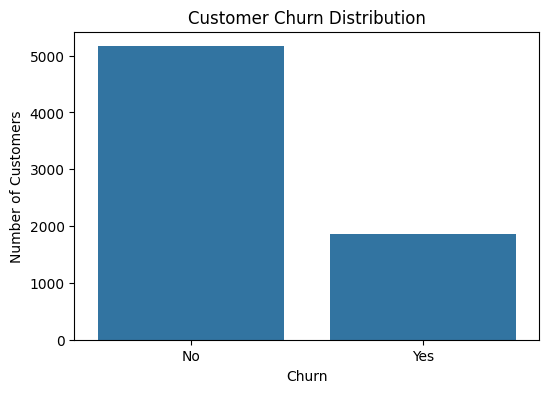

,proportion
Churn,
No,73.421502
Yes,26.578498


In [9]:
# Churn distribution
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

# Percentage of churn
df['Churn'].value_counts(normalize=True) * 100

## 4. Exploratory data analysis

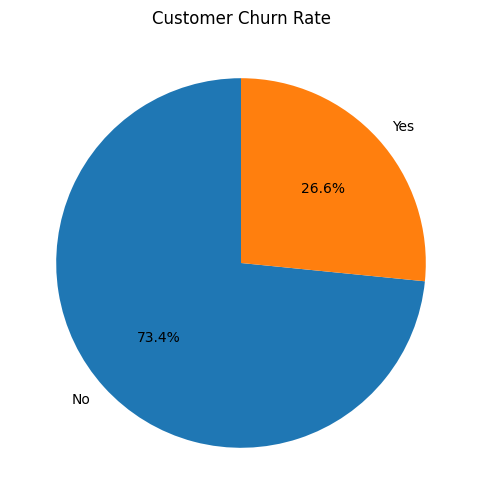

In [10]:
# Churn percentage
churn_rate = df['Churn'].value_counts(normalize=True) * 100

plt.figure(figsize=(6,6))
plt.pie(churn_rate,
        labels=churn_rate.index,
        autopct='%1.1f%%',
        startangle=90)

plt.title('Customer Churn Rate')
plt.show()

## 4. Exploratory data analysis

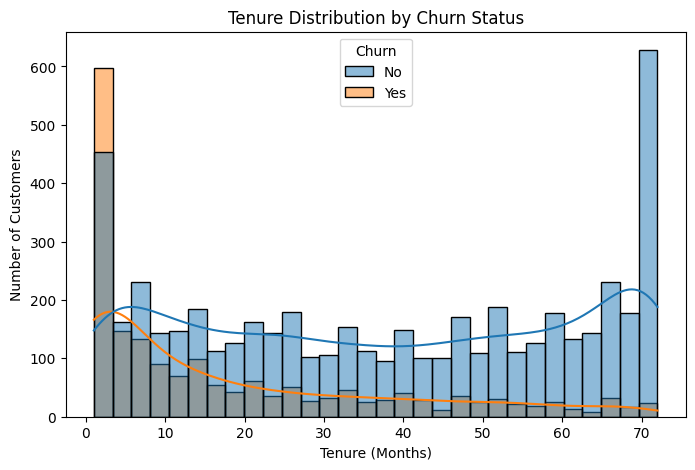

In [11]:
# Tenure distribution by churn
plt.figure(figsize=(8,5))
sns.histplot(data=df,
             x='tenure',
             hue='Churn',
             bins=30,
             kde=True)

plt.title('Tenure Distribution by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

## 4. Exploratory data analysis

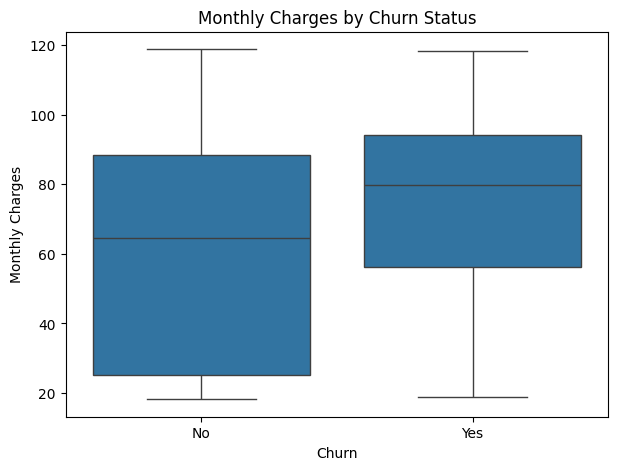

In [12]:
# Monthly charges by churn
plt.figure(figsize=(7,5))
sns.boxplot(data=df,
            x='Churn',
            y='MonthlyCharges')

plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()

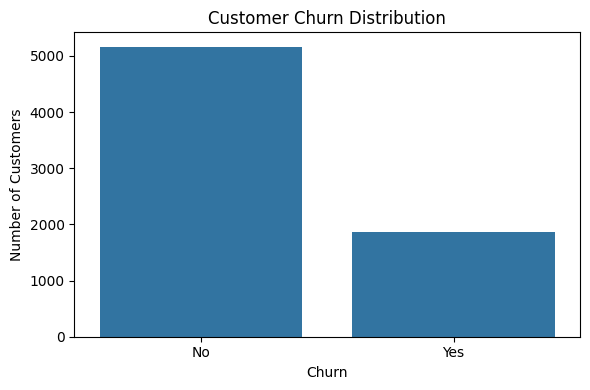

In [13]:
# Save churn distribution plot
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.savefig('churn_distribution.png', dpi=300)

plt.show()

In [15]:
# Set visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8,5)
plt.rcParams['font.size'] = 11

## 5. Feature engineering

In [16]:
# Remove customerID
df = df.drop('customerID', axis=1)

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 5. Feature engineering

In [17]:
# Encode target variable
df['Churn'] = df['Churn'].map({'No':0, 'Yes':1})

df['Churn'].value_counts()

,count
Churn,
0,5163
1,1869


## 5. Feature engineering

In [18]:
# Convert categorical variables to dummy variables
df_encoded = pd.get_dummies(df, drop_first=True)

df_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False


In [19]:
from sklearn.model_selection import train_test_split

# Features and target
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(5625, 30)
(1407, 30)


In [20]:
from sklearn.preprocessing import StandardScaler

# Columns to scale
scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()

X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

X_train.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
1413,0,1.321816,0.981556,1.659900,True,True,True,True,False,True,True,False,False,True,False,True,False,True,False,True,False,False,False,False,False,True,False,True,False,False
7003,0,-0.267410,-0.971546,-0.562252,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,True,False
3355,0,1.444064,0.837066,1.756104,False,True,False,True,False,True,True,False,False,False,False,True,False,True,False,True,False,False,False,False,False,True,False,True,False,False
4494,0,-1.204646,0.641092,-0.908326,True,False,False,True,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,True,False
3541,0,0.669826,-0.808787,-0.101561,False,True,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False


## 6. Logistic regression model

In [21]:
from sklearn.linear_model import LogisticRegression

# Train logistic regression model
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train, y_train)

# Predict
y_pred = log_model.predict(X_test)

print('Model training completed!')

Model training completed!


In [22]:
from sklearn.metrics import accuracy_score, classification_report

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.3f}')

# Classification report
print(classification_report(y_test, y_pred))

Accuracy: 0.805
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



## 6. Logistic regression model

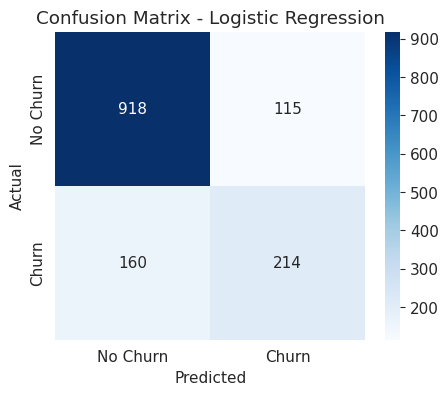

In [23]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

## 7. Random forest model

In [24]:
from sklearn.metrics import roc_auc_score, roc_curve

# Predicted probabilities
y_prob = log_model.predict_proba(X_test)[:,1]

# ROC AUC
auc = roc_auc_score(y_test, y_prob)
print(f'ROC AUC: {auc:.3f}')

ROC AUC: 0.836


## 6. Logistic regression model

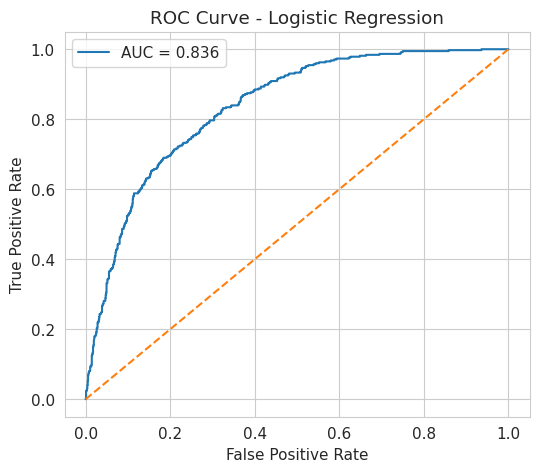

In [25]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0,1], [0,1], linestyle='--')

plt.title('ROC Curve - Logistic Regression')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.show()

## 7. Random forest model

In [26]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=8
)

rf_model.fit(X_train, y_train)

# Predict
y_pred_rf = rf_model.predict(X_test)

print('Random Forest training completed!')

Random Forest training completed!


In [27]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# Accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f'Random Forest Accuracy: {accuracy_rf:.3f}')

# Classification report
print(classification_report(y_test, y_pred_rf))

# ROC AUC
y_prob_rf = rf_model.predict_proba(X_test)[:,1]
auc_rf = roc_auc_score(y_test, y_prob_rf)

print(f'Random Forest ROC AUC: {auc_rf:.3f}')

Random Forest Accuracy: 0.791
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.64      0.48      0.55       374

    accuracy                           0.79      1407
   macro avg       0.74      0.69      0.71      1407
weighted avg       0.78      0.79      0.78      1407

Random Forest ROC AUC: 0.838


## 7. Random forest model

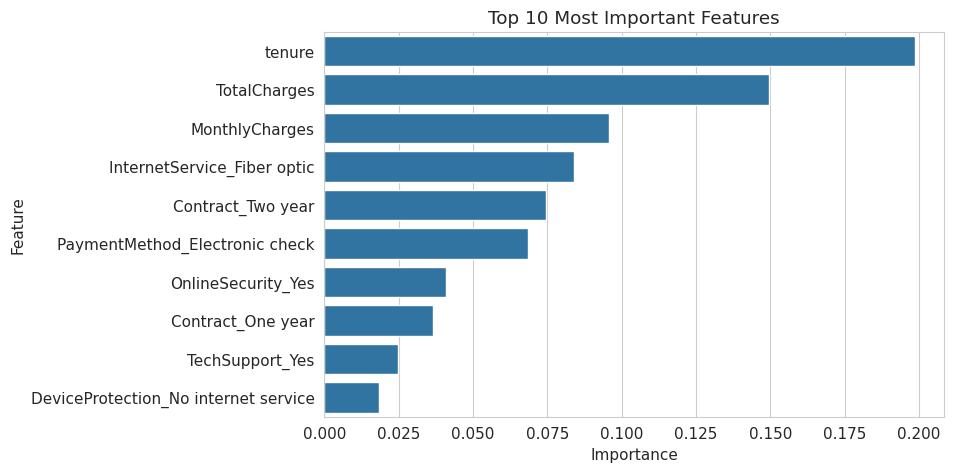

In [28]:
# Feature importance
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

plt.figure(figsize=(8,5))
sns.barplot(data=importance,
            x='Importance',
            y='Feature')

plt.title('Top 10 Most Important Features')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

## 8. Model comparison

In [29]:
# Model comparison
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy, accuracy_rf],
    'ROC AUC': [auc, auc_rf]
})

comparison

,Model,Accuracy,ROC AUC
0,Logistic Regression,0.804549,0.836071
1,Random Forest,0.791045,0.838370


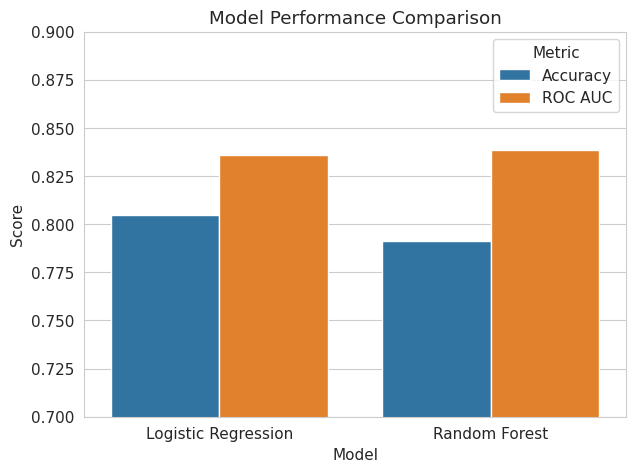

In [30]:
comparison_melt = comparison.melt(id_vars='Model',
                                  var_name='Metric',
                                  value_name='Score')

plt.figure(figsize=(7,5))
sns.barplot(data=comparison_melt,
            x='Model',
            y='Score',
            hue='Metric')

plt.title('Model Performance Comparison')
plt.ylim(0.7, 0.9)

plt.show()

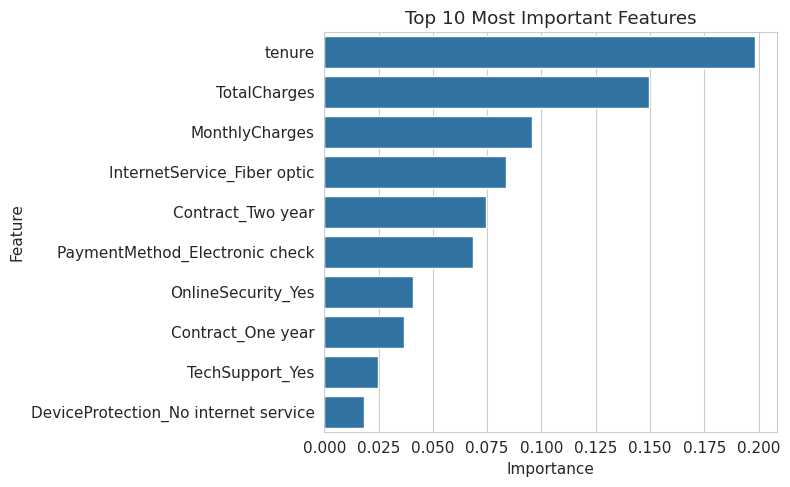

In [31]:
plt.figure(figsize=(8,5))
sns.barplot(data=importance,
            x='Importance',
            y='Feature')

plt.title('Top 10 Most Important Features')

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)

plt.show()

# Customer churn prediction using machine learning

This project predicts customer churn using the Telco Customer Churn dataset. The analysis includes data cleaning, exploratory data analysis (EDA), feature engineering, and machine learning model comparison.

## 9. Feature importance and business insights

The Random Forest model identified **tenure** as the strongest predictor of customer churn, followed by **TotalCharges**, **MonthlyCharges**, and **contract type**.

### Key business insights

* **Customers with short tenure are the most likely to churn.** This suggests that the first few months are critical for customer retention.
* **Higher monthly charges are associated with a greater probability of churn.** Customers paying higher fees may be more sensitive to price or service value.
* **Customers with two-year contracts are less likely to churn**, indicating that longer contract commitments improve retention.
* **Fiber optic internet customers show relatively higher churn importance**, suggesting that service experience and pricing should be monitored closely in this segment.

### Business implication

The company should prioritize **early retention campaigns**, **contract renewal strategies**, and **targeted interventions for high-value customers with short tenure and high monthly charges**. These actions could reduce churn and improve customer lifetime value.
